In [ ]:
import sqlite3

# SQLiteデータベースを作成
conn = sqlite3.connect("cabbage.db")

In [ ]:
import pandas as pd

# CSVファイルを読み込む
reference_2023 = pd.read_csv(
    "2023_trey cabbage_data_reference.csv"
)

reference_2024 = pd.read_csv(
    "2024_trey cabbage_data_reference.csv"
)

savant_2023 = pd.read_csv(
    "savant_2023_trey cabbage.csv"
)

savant_2024 = pd.read_csv(
    "savant_2024_trey cabbage.csv"
)

savant_sprint_speed_2024 = pd.read_csv(
    "sprint_speed_2024.csv"
)

In [ ]:
# 2023年Referenceデータをテーブルに登録
reference_2023.to_sql(
    "reference_2023",
    conn,
    if_exists="replace",
    index=False
)

# 2024年Referenceデータをテーブルに登録
reference_2024.to_sql(
    "reference_2024",
    conn,
    if_exists="replace",
    index=False
)

# 2023年Savantデータをテーブルに登録
savant_2023.to_sql(
    "savant_2023",
    conn,
    if_exists="replace",
    index=False
)

# 2024年Savantデータをテーブルに登録
savant_2024.to_sql(
    "savant_2024",
    conn,
    if_exists="replace",
    index=False
)

# 2024年Sprint Speedデータをテーブルに登録
savant_sprint_speed_2024.to_sql(
    "savant_sprint_speed_2024",
    conn,
    if_exists="replace",
    index=False
)

566

In [ ]:
# 2023年の主要打撃成績を取得
query = """
SELECT
    G AS 試合数,
    PA AS 打席数,
    BA AS 打率,
    OBP AS 出塁率,
    SLG AS 長打率,
    OPS,
    HR AS 本塁打,
    RBI AS 打点,
    BB AS 四球,
    SO AS 三振,
    ROUND(BB * 100.0 / PA, 1) AS 四球率,
    ROUND(SO * 100.0 / PA, 1) AS 三振率,
    SB AS 盗塁,
    CS AS 盗塁死
FROM reference_2023;
"""

# SQLを実行してデータを取得
main_stats_2023 = pd.read_sql_query(query, conn)

main_stats_2023

,試合数,打席数,打率,出塁率,長打率,OPS,本塁打,打点,四球,三振,四球率,三振率,盗塁,盗塁死
0,22,56,0.208,0.232,0.321,0.553,1,7,2,26,3.6,46.4,1,1


In [ ]:
# 2024年の主要打撃成績を取得
query = """
SELECT
    G AS 試合数,
    PA AS 打席数,
    BA AS 打率,
    OBP AS 出塁率,
    SLG AS 長打率,
    OPS,
    HR AS 本塁打,
    RBI AS 打点,
    BB AS 四球,
    SO AS 三振,
    ROUND(BB * 100.0 / PA, 1) AS 四球率,
    ROUND(SO * 100.0 / PA, 1) AS 三振率,
    SB AS 盗塁,
    CS AS 盗塁死
FROM reference_2024;
"""

# SQLを実行してデータを取得
main_stats_2024 = pd.read_sql_query(query, conn)

main_stats_2024

,試合数,打席数,打率,出塁率,長打率,OPS,本塁打,打点,四球,三振,四球率,三振率,盗塁,盗塁死
0,45,91,0.209,0.253,0.337,0.59,1,8,4,34,4.4,37.4,1,1


In [ ]:
from IPython.display import display, HTML
import pandas as pd

# 2023年・2024年の主要成績を比較用に整形
main_stats_display = pd.DataFrame({
    "指標": [
        "試合数 (G)",
        "打席数 (PA)",
        "打率 (BA)",
        "出塁率 (OBP)",
        "長打率 (SLG)",
        "OPS",
        "本塁打 (HR)",
        "打点 (RBI)",
        "四球率 (BB%)",
        "三振率 (K%)"
    ],
    "2023年": [
        int(main_stats_2023.iloc[0]["試合数"]),
        int(main_stats_2023.iloc[0]["打席数"]),
        f"{float(main_stats_2023.iloc[0]['打率']):.3f}",
        f"{float(main_stats_2023.iloc[0]['出塁率']):.3f}",
        f"{float(main_stats_2023.iloc[0]['長打率']):.3f}",
        f"{float(main_stats_2023.iloc[0]['OPS']):.3f}",
        int(main_stats_2023.iloc[0]["本塁打"]),
        int(main_stats_2023.iloc[0]["打点"]),
        f"{float(main_stats_2023.iloc[0]['四球率']):.1f}%",
        f"{float(main_stats_2023.iloc[0]['三振率']):.1f}%"
    ],
    "2024年": [
        int(main_stats_2024.iloc[0]["試合数"]),
        int(main_stats_2024.iloc[0]["打席数"]),
        f"{float(main_stats_2024.iloc[0]['打率']):.3f}",
        f"{float(main_stats_2024.iloc[0]['出塁率']):.3f}",
        f"{float(main_stats_2024.iloc[0]['長打率']):.3f}",
        f"{float(main_stats_2024.iloc[0]['OPS']):.3f}",
        int(main_stats_2024.iloc[0]["本塁打"]),
        int(main_stats_2024.iloc[0]["打点"]),
        f"{float(main_stats_2024.iloc[0]['四球率']):.1f}%",
        f"{float(main_stats_2024.iloc[0]['三振率']):.1f}%"
    ]
})

# HTMLを作成
html = """
<h3 style="text-align:center;">キャベッジのMLB主要打撃成績（2023〜2024年）</h3>

<table style="
    border-collapse: collapse;
    width: 80%;
    margin: auto;
    table-layout: fixed;
">
    <thead>
        <tr>
            <th style="
                width: 40%;
                border: 1px solid black;
                text-align: center;
                padding: 8px;
                background-color: #F2F2F2;
            ">指標</th>

            <th style="
                width: 30%;
                border: 1px solid black;
                text-align: center;
                padding: 8px;
                background-color: #F2F2F2;
            ">2023年</th>

            <th style="
                width: 30%;
                border: 1px solid black;
                text-align: center;
                padding: 8px;
                background-color: #F2F2F2;
            ">2024年</th>
        </tr>
    </thead>

    <tbody>
"""

# 表の行を作成
for _, row in main_stats_display.iterrows():

    # 注目項目を赤字にする
    highlight = row["指標"] in [
        "打席数 (PA)",
        "OPS",
        "三振率 (K%)"
    ]

    color = "#D32F2F" if highlight else "black"
    weight = "bold" if highlight else "normal"

    html += f"""
    <tr>
        <td style="
            border: 1px solid black;
            text-align: center;
            padding: 8px;
            color: {color};
            font-weight: {weight};
        ">{row['指標']}</td>

        <td style="
            border: 1px solid black;
            text-align: center;
            padding: 8px;
            color: {color};
            font-weight: {weight};
        ">{row['2023年']}</td>

        <td style="
            border: 1px solid black;
            text-align: center;
            padding: 8px;
            color: {color};
            font-weight: {weight};
        ">{row['2024年']}</td>
    </tr>
    """

html += """
    </tbody>
</table>
"""

display(HTML(html))

指標,2023年,2024年
試合数 (G),22,45
打席数 (PA),56,91
打率 (BA),0.208,0.209
出塁率 (OBP),0.232,0.253
長打率 (SLG),0.321,0.337
OPS,0.553,0.590
本塁打 (HR),1,1
打点 (RBI),7,8
四球率 (BB%),3.6%,4.4%
三振率 (K%),46.4%,37.4%


In [ ]:
# 2023年の打球データを取得
query = """
SELECT
    launch_speed AS 平均打球速度,
    hardhit_percent AS ハードヒット率,
    barrels_per_bbe_percent AS バレル率,
    launch_angle AS 平均打球角度
FROM savant_2023
WHERE player_name LIKE '%Cabbage%';
"""

# SQLを実行してデータを取得
batting_quality_2023 = pd.read_sql_query(query, conn)

batting_quality_2023

,平均打球速度,ハードヒット率,バレル率,平均打球角度
0,86.7,32.142857,7.142857,4.7


In [ ]:
# 2024年の打球データを取得
query = """
SELECT
    launch_speed AS 平均打球速度,
    hardhit_percent AS ハードヒット率,
    barrels_per_bbe_percent AS バレル率,
    launch_angle AS 平均打球角度
FROM savant_2024
WHERE player_name LIKE '%Cabbage%';
"""

# SQLを実行してデータを取得
batting_quality_2024 = pd.read_sql_query(query, conn)

batting_quality_2024

,平均打球速度,ハードヒット率,バレル率,平均打球角度
0,91.5,54.901961,15.686275,7.3


In [ ]:
from IPython.display import display, HTML
import pandas as pd

# 2023年・2024年の打球の質を比較用に整形
batting_quality_display = pd.DataFrame({
    "指標": [
        "平均打球速度(mph)",
        "ハードヒット率",
        "バレル率",
        "平均打球角度"
    ],
    "2023年": [
        f"{float(batting_quality_2023.iloc[0]['平均打球速度']):.1f}",
        f"{float(batting_quality_2023.iloc[0]['ハードヒット率']):.1f}%",
        f"{float(batting_quality_2023.iloc[0]['バレル率']):.1f}%",
        f"{float(batting_quality_2023.iloc[0]['平均打球角度']):.1f}°"
    ],
    "2024年": [
        f"{float(batting_quality_2024.iloc[0]['平均打球速度']):.1f}",
        f"{float(batting_quality_2024.iloc[0]['ハードヒット率']):.1f}%",
        f"{float(batting_quality_2024.iloc[0]['バレル率']):.1f}%",
        f"{float(batting_quality_2024.iloc[0]['平均打球角度']):.1f}°"
    ],
    # MLB平均は手入力
    "MLB平均": [
        "88.6",
        "37.1%",
        "7.6%",
        "12.6°"
    ]
})

# HTMLを作成
html = """
<table style="
    border-collapse: collapse;
    width: 90%;
    margin: auto;
    table-layout: fixed;
">
    <thead>
        <tr>
            <th style="width: 28%; border: 1px solid black; text-align: center; padding: 8px; background-color: #F2F2F2;">指標</th>
            <th style="width: 24%; border: 1px solid black; text-align: center; padding: 8px; background-color: #F2F2F2;">2023年</th>
            <th style="width: 24%; border: 1px solid black; text-align: center; padding: 8px; background-color: #F2F2F2;">2024年</th>
            <th style="width: 24%; border: 1px solid black; text-align: center; padding: 8px; background-color: #F2F2F2;">MLB平均</th>
        </tr>
    </thead>
    <tbody>
"""

# 表の行を作成
for _, row in batting_quality_display.iterrows():
    html += f"""
    <tr>
        <td style="border: 1px solid black; text-align: center; padding: 8px;">{row['指標']}</td>
        <td style="border: 1px solid black; text-align: center; padding: 8px;">{row['2023年']}</td>
        <td style="border: 1px solid black; text-align: center; padding: 8px;">{row['2024年']}</td>
        <td style="border: 1px solid black; text-align: center; padding: 8px;">{row['MLB平均']}</td>
    </tr>
    """

html += """
    </tbody>
</table>

<p style="text-align:center; font-size:12px;">
※ MLB平均は2015年以降の歴史的な参考値。
</p>
"""

display(HTML(html))

指標,2023年,2024年,MLB平均
平均打球速度(mph),86.7,91.5,88.6
ハードヒット率,32.1%,54.9%,37.1%
バレル率,7.1%,15.7%,7.6%
平均打球角度,4.7°,7.3°,12.6°


In [ ]:
# 2023年の打撃アプローチ・コンタクト指標を取得
query = """
SELECT
    ROUND(swings * 100.0 / (swings + takes), 1) AS スイング率,
    swing_miss_percent AS 空振り率
FROM savant_2023
WHERE player_name LIKE '%Cabbage%';
"""

approach_2023 = pd.read_sql_query(query, conn)

approach_2023

,スイング率,空振り率
0,65.1,51.4


In [ ]:
# 2024年の打撃アプローチ・コンタクト指標を取得
query = """
SELECT
    ROUND(swings * 100.0 / (swings + takes), 1) AS スイング率,
    swing_miss_percent AS 空振り率
FROM savant_2024
WHERE player_name LIKE '%Cabbage%';
"""

approach_2024 = pd.read_sql_query(query, conn)

approach_2024

,スイング率,空振り率
0,52.7,40.7


In [ ]:
!apt-get update -qq
!apt-get install -y fonts-noto-cjk -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-noto-cjk.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-noto-cjk_1%3a20230817+repack1-3_all.deb ...
Unpacking fonts-noto-cjk (1:20230817+repack1-3) ...
Setting up fonts-noto-cjk (1:20230817+repack1-3) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


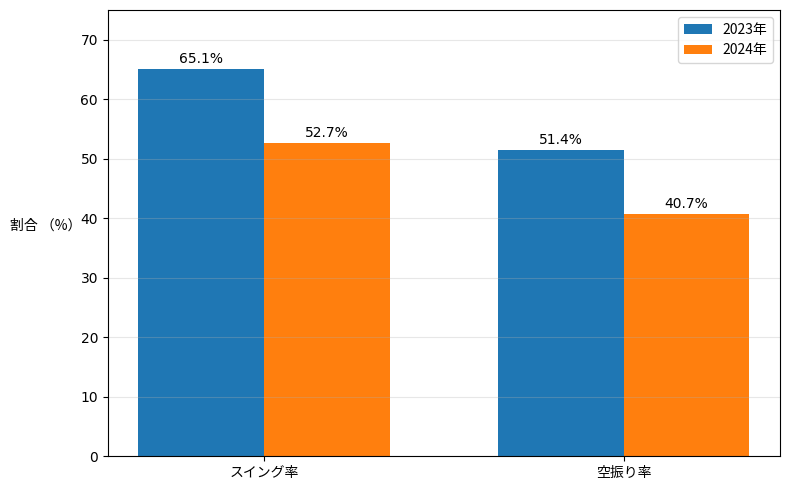

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# 日本語フォントを指定
font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_prop = fm.FontProperties(fname=font_path)

# SQLで抽出したデータを使用
metrics = ["スイング率", "空振り率"]

values_2023 = [
    float(approach_2023.iloc[0]["スイング率"]),
    float(approach_2023.iloc[0]["空振り率"])
]

values_2024 = [
    float(approach_2024.iloc[0]["スイング率"]),
    float(approach_2024.iloc[0]["空振り率"])
]

# x軸の位置
x = np.arange(len(metrics))
width = 0.35

# グラフ作成
fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    values_2023,
    width,
    label="2023年"
)

bars2 = ax.bar(
    x + width / 2,
    values_2024,
    width,
    label="2024年"
)

# 軸
ax.set_ylabel(
    "割合 （%）",
    fontproperties=font_prop,
    rotation=0,
    labelpad=25
)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontproperties=font_prop)
ax.set_ylim(0, 75)

# 凡例
ax.legend(prop=font_prop)

# 数値ラベル
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.1f}%",
            ha="center"
        )

# 横線
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 2023年の実績値と期待値を取得
query = """
SELECT
    ba AS 打率,
    xba AS 期待打率,
    slg AS 長打率,
    xslg AS 期待長打率,
    woba AS wOBA,
    xwoba AS 期待wOBA
FROM savant_2023
WHERE player_name LIKE '%Cabbage%';
"""

expected_2023 = pd.read_sql_query(query, conn)

expected_2023

,打率,期待打率,長打率,期待長打率,wOBA,期待wOBA
0,0.208,0.141,0.321,0.246,0.238,0.183


In [ ]:
# 2024年の実績値と期待値を取得
query = """
SELECT
    ba AS 打率,
    xba AS 期待打率,
    slg AS 長打率,
    xslg AS 期待長打率,
    woba AS wOBA,
    xwoba AS 期待wOBA
FROM savant_2024
WHERE player_name LIKE '%Cabbage%';
"""

expected_2024 = pd.read_sql_query(query, conn)

expected_2024

,打率,期待打率,長打率,期待長打率,wOBA,期待wOBA
0,0.209,0.188,0.337,0.358,0.258,0.261


In [ ]:
from IPython.display import display, HTML
import pandas as pd

# 小数点以下3桁で表示（0.141 → .141）
def format_stat(value):
    return f"{float(value):.3f}".replace("0.", ".", 1)

# 表示用データを作成
table_data = [
    ("BA(打率)",
     format_stat(expected_2023.iloc[0]["打率"]),
     format_stat(expected_2024.iloc[0]["打率"]),
     "actual"),

    ("xBA(期待打率)",
     format_stat(expected_2023.iloc[0]["期待打率"]),
     format_stat(expected_2024.iloc[0]["期待打率"]),
     "expected"),

    ("SLG(長打率)",
     format_stat(expected_2023.iloc[0]["長打率"]),
     format_stat(expected_2024.iloc[0]["長打率"]),
     "actual"),

    ("xSLG(期待長打率)",
     format_stat(expected_2023.iloc[0]["期待長打率"]),
     format_stat(expected_2024.iloc[0]["期待長打率"]),
     "expected"),

    ("wOBA",
     format_stat(expected_2023.iloc[0]["wOBA"]),
     format_stat(expected_2024.iloc[0]["wOBA"]),
     "actual"),

    ("xwOBA(期待wOBA)",
     format_stat(expected_2023.iloc[0]["期待wOBA"]),
     format_stat(expected_2024.iloc[0]["期待wOBA"]),
     "expected")
]

# HTMLテーブルを作成
html = """
<table style="
    width: 90%;
    border-collapse: collapse;
    table-layout: fixed;
    font-size: 17px;
    color: #222;
    margin: 20px auto;
">
    <thead>
        <tr style="border-bottom: 2px solid #cccccc;">
            <th style="width: 50%; text-align: left; padding: 12px 10px;">
                指標
            </th>
            <th style="width: 25%; text-align: right; padding: 12px 20px;">
                2023年
            </th>
            <th style="width: 25%; text-align: right; padding: 12px 20px;">
                2024年
            </th>
        </tr>
    </thead>
    <tbody>
"""

for metric, value_2023, value_2024, category in table_data:

    # 実績と期待値で背景色を変更
    background = "#F0F3F6" if category == "expected" else "#FFFFFF"

    # 期待値の行の下にグループ区切り線を設定
    border = "2px solid #555555" if category == "expected" else "1px solid #E5E5E5"

    html += f"""
        <tr style="
            background-color: {background};
            border-bottom: {border};
        ">
            <td style="text-align: left; padding: 17px 10px;">
                {metric}
            </td>
            <td style="text-align: right; padding: 17px 20px;">
                {value_2023}
            </td>
            <td style="text-align: right; padding: 17px 20px;">
                {value_2024}
            </td>
        </tr>
    """

html += """
    </tbody>
</table>

<p style="
    width: 90%;
    margin: 10px auto;
    font-size: 12px;
    color: #666666;
">
※ xBA・xSLG・xwOBAはStatcastのモデルによる期待値。
</p>
"""

display(HTML(html))

指標,2023年,2024年
BA(打率),.208,.209
xBA(期待打率),.141,.188
SLG(長打率),.321,.337
xSLG(期待長打率),.246,.358
wOBA,.238,.258
xwOBA(期待wOBA),.183,.261


In [ ]:
# 2024年のキャベッジのスプリントスピードを取得
query = """
SELECT
    sprint_speed
FROM savant_sprint_speed_2024
WHERE "last_name, first_name" LIKE '%Cabbage%';
"""

cabbage_speed_2024 = pd.read_sql_query(query, conn)

display(cabbage_speed_2024)

,sprint_speed
0,27.9


In [ ]:
from IPython.display import display, HTML

# キャベッジのスプリントスピード
cabbage_speed = float(cabbage_speed_2024.iloc[0]["sprint_speed"])

html = f"""
<table style="width:90%; border-collapse:collapse; table-layout:fixed; font-size:17px; color:#222; margin:20px auto;">
<thead>
<tr style="border-bottom:2px solid #cccccc;">
<th style="width:50%; text-align:left; padding:12px 10px;">指標</th>
<th style="width:25%; text-align:right; padding:12px 20px;">キャベッジ選手</th>
<th style="width:25%; text-align:right; padding:12px 20px;">MLBの走力の目安</th>
</tr>
</thead>
<tbody>
<tr style="background-color:#FFFFFF; border-bottom:2px solid #555555;">
<td style="text-align:left; padding:17px 10px;">
スプリントスピード（Sprint Speed）
</td>
<td style="text-align:right; padding:17px 20px;">
{cabbage_speed:.1f} ft/sec
</td>
<td style="text-align:right; padding:17px 20px;">
27.0 ft/sec
</td>
</tr>
</tbody>
</table>

<p style="width:90%; margin:10px auto; font-size:12px; color:#666666;">
※ MLBの走力の目安は、Statcastが示す競争的な走塁における平均的なスピード（27.0 ft/sec）。
30.0 ft/sec以上はエリート水準とされる。
</p>
"""

display(HTML(html))

指標,キャベッジ選手,MLBの走力の目安
スプリントスピード（Sprint Speed）,27.9 ft/sec,27.0 ft/sec
